In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)

from data_loader import DataLoader
import project_images_loader as pil

import tensorflow as tf

import discriminator as Discriminator
import generator as Generator

import util.functions as fc



2024-02-29 18:41:15.167588: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-02-29 18:41:15.207630: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-29 18:41:15.207660: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-29 18:41:15.208872: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-02-29 18:41:15.216237: I tensorflow/core/platform/cpu_feature_guar

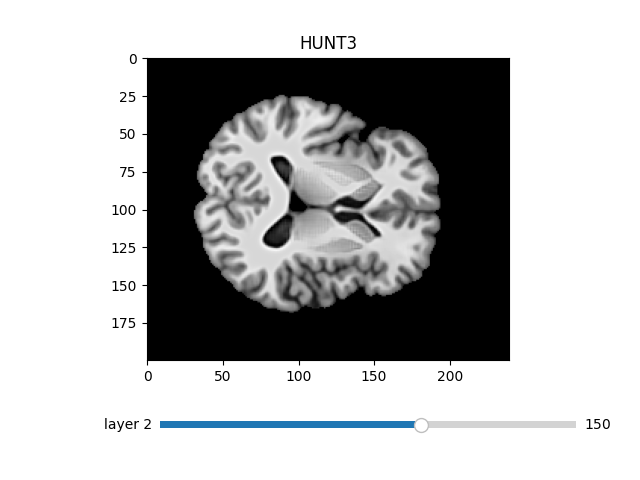

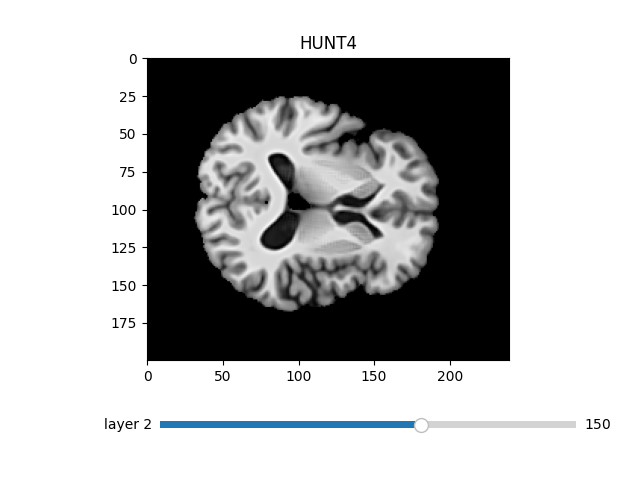

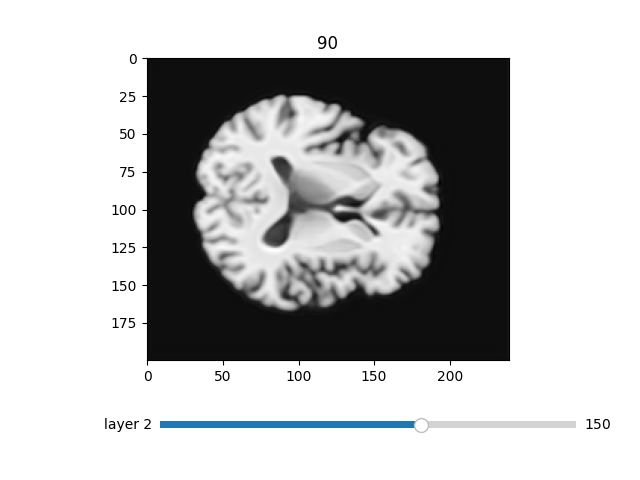

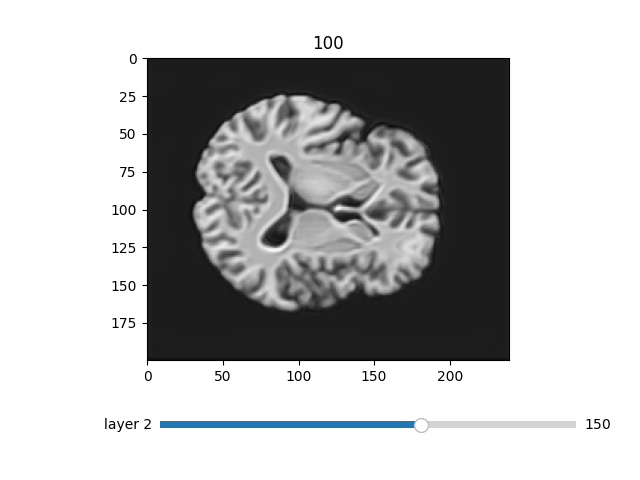

In [6]:
%matplotlib widget

input_shape = (200, 240, 240)

D = Discriminator.create_discriminator_model(input_shape)
G = Generator.create_generator_model(input_shape)

data_train = DataLoader(f"{pil.get_data_reduced_folder(absolute=True)}/train", batch_size=1, image_size=input_shape, shuffle=True, channels_first=False)
data = data_train[0]

fc.imgshow_3D(f"HUNT3", data[0][0,...,0], current_plane=150)
fc.imgshow_3D(f"HUNT4", data[1][0,...,0], current_plane=150)
# plot(data[1][0,...,0])
for epoch in range(90,101,10):
    G.load_weights(f"{current_path}/models/generator{epoch}.h5")
    img_generated = G(data[0])
    fc.imgshow_3D(f"{epoch}", img_generated[0,...,0], current_plane=150)
    # plot(img_generated[0,...,0])

